In [ ]:
# Librerías necesarias
!pip install transformers datasets torch pandas matplotlib seaborn


In [ ]:
import pandas as pd

train_nb15= pd.read_csv('/content/UNSW_NB15_training-set.csv')
test_nb15 = pd.read_csv('/content/UNSW_NB15_testing-set.csv')

# Verificar Registros
train_nb15['label'].value_counts()
train_nb15['attack_cat'].value_counts()


,count
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133


In [ ]:
# ==== Semillas para reproducibilidad ====
import os, random, numpy as np, torch
from transformers import set_seed

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# para que cuDNN no cambie heurísticas entre ejecuciones
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# utilidad de transformers (afecta generadores internos)
set_seed(SEED)
# =======================================

print("✅ Datos cargados")
print("Entrenamiento:", train_nb15.shape)
print("Pruebas:", test_nb15.shape)

train_nb15.head()


✅ Datos cargados
Entrenamiento: (175341, 45)
Pruebas: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [ ]:
# === Usar dataset completo (sin reducción de muestras) ===
train_df_full = train_nb15.copy()
test_df_full  = test_nb15.copy()

# Construcción de la secuencia textual
train_df_full['text'] = train_df_full['proto'] + " " + train_df_full['service'] + " " + train_df_full['state']
test_df_full['text']  = test_df_full['proto']  + " " + test_df_full['service']  + " " + test_df_full['state']

In [ ]:
# === Reducir entrenamiento con muestra estratificada y balanceada por 'label' ===

def balanced_by_label(df, label_col, max_total, random_state):
    vc = df[label_col].value_counts()
    clases = vc.index.tolist()
    per_class = max_total // len(clases)

    partes = []
    for c in clases:
        n = min(per_class, int(vc[c]))
        partes.append(df[df[label_col] == c].sample(n=n, replace=False, random_state=random_state))

    out = pd.concat(partes, axis=0).sample(frac=1.0, random_state=random_state).reset_index(drop=True)
    return out

# Ajusta max_total al tamaño que quieras usar en entrenamiento
train_df_full = balanced_by_label(train_df_full, label_col='label', max_total=15_000, random_state=SEED)



In [ ]:
# === TOKENIZADOR GPT-2
from transformers import GPT2TokenizerFast, GPT2ForSequenceClassification

MAX_LEN = 16
gpt_tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
gpt_tokenizer.pad_token = gpt_tokenizer.eos_token
gpt_tokenizer.padding_side = "right"

train_encodings_gpt = gpt_tokenizer(
    train_df_full["text"].tolist(),
    truncation=True, padding="max_length", max_length=MAX_LEN
)
test_encodings_gpt = gpt_tokenizer(
    test_df_full["text"].tolist(),
    truncation=True, padding="max_length", max_length=MAX_LEN
)
# carga del modelo
model = GPT2ForSequenceClassification.from_pretrained("gpt2", num_labels=2)
model.config.pad_token_id = gpt_tokenizer.pad_token_id

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch

class TextClsDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx], dtype=torch.long) for k, v in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_dataset = TextClsDataset(train_encodings_gpt, list(train_df_full['label']))
test_dataset  = TextClsDataset(test_encodings_gpt,  list(test_df_full['label']))

g = torch.Generator(); g.manual_seed(SEED)  # para reproducibilidad en el shuffle
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, generator=g)
test_loader  = DataLoader(test_dataset,  batch_size=16)

print("✅ DataLoaders listos")
print("Batches de entrenamiento:", len(train_loader))
print("Batches de prueba:", len(test_loader))



✅ DataLoaders listos
Batches de entrenamiento: 938
Batches de prueba: 5146


In [ ]:
from torch.optim import AdamW
from torch.nn import CrossEntropyLoss
import torch.nn.utils as nn_utils

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

LR = 5e-5
MAX_GRAD_NORM = 1.0

optimizer = AdamW(model.parameters(), lr=LR)

# === Calcular pesos de clase ===
class_counts = train_df_full['label'].value_counts().sort_index().to_numpy()
class_weights = torch.tensor(1.0 / class_counts, dtype=torch.float).to(device)
print("Pesos de clase:", class_weights)

criterion = CrossEntropyLoss(weight=class_weights)

# === Loop de entrenamiento con pesos ===
model.train()
for epoch in range(5):   # usa 3 para comparativa; ajusta después si hace falta
    epoch_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        outputs = model(
            batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device)
        )
        loss = criterion(outputs.logits, batch['labels'].to(device))
        loss.backward()
        nn_utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)
        optimizer.step()
        epoch_loss += loss.item()
    avg_loss = epoch_loss / len(train_loader)
    print(f"✅ Época {epoch+1} completada – Loss ponderado promedio: {avg_loss:.4f}")


Pesos de clase: tensor([0.0001, 0.0001], device='cuda:0')
✅ Época 1 completada – Loss ponderado promedio: 0.4257
✅ Época 2 completada – Loss ponderado promedio: 0.3674
✅ Época 3 completada – Loss ponderado promedio: 0.3637
✅ Época 4 completada – Loss ponderado promedio: 0.3599
✅ Época 5 completada – Loss ponderado promedio: 0.3709


📊 Precisión (accuracy) del modelo GPT en UNSW-NB15: 77.53%
              precision    recall  f1-score   support

      Normal       0.76      0.76      0.76     37000
      Ataque       0.80      0.81      0.81     45332

    accuracy                           0.79     82332
   macro avg       0.78      0.78      0.78     82332
weighted avg       0.79      0.79      0.79     82332



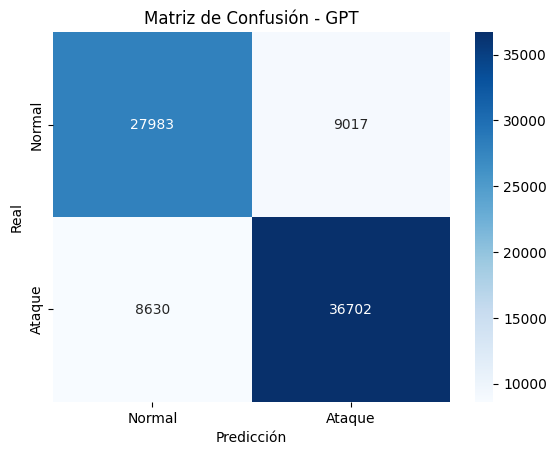

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np, seaborn as sns, matplotlib.pyplot as plt
import torch

model.eval()

# Accuracy (precisión global)
correct, total = 0, 0
with torch.no_grad():
    for batch in test_loader:  # sin shuffle
        out = model(
            batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device)
        )
        preds = torch.argmax(out.logits, dim=1)
        correct += (preds.cpu() == batch['labels']).sum().item()
        total   += batch['labels'].size(0)
acc = correct / total
print(f"📊 Precisión (accuracy) del modelo GPT en UNSW-NB15: {acc:.2%}")

# Reporte detallado y matriz de confusión
all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for batch in test_loader:
        out = model(
            batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device)
        )
        probs = torch.softmax(out.logits, dim=-1)   # obtenemos probabilidades
        preds = (probs[:,1] >= 0.4).long()          # ajustamos umbral a 0.4 para clase "Ataque"
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch['labels'].cpu().numpy())

print(classification_report(
    all_labels, all_preds,
    target_names=['Normal','Ataque'],
    digits=2, zero_division=0
))

cm = confusion_matrix(all_labels, all_preds, labels=[0,1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Ataque'], yticklabels=['Normal','Ataque'])
plt.xlabel('Predicción'); plt.ylabel('Real'); plt.title('Matriz de Confusión - GPT')
plt.show()


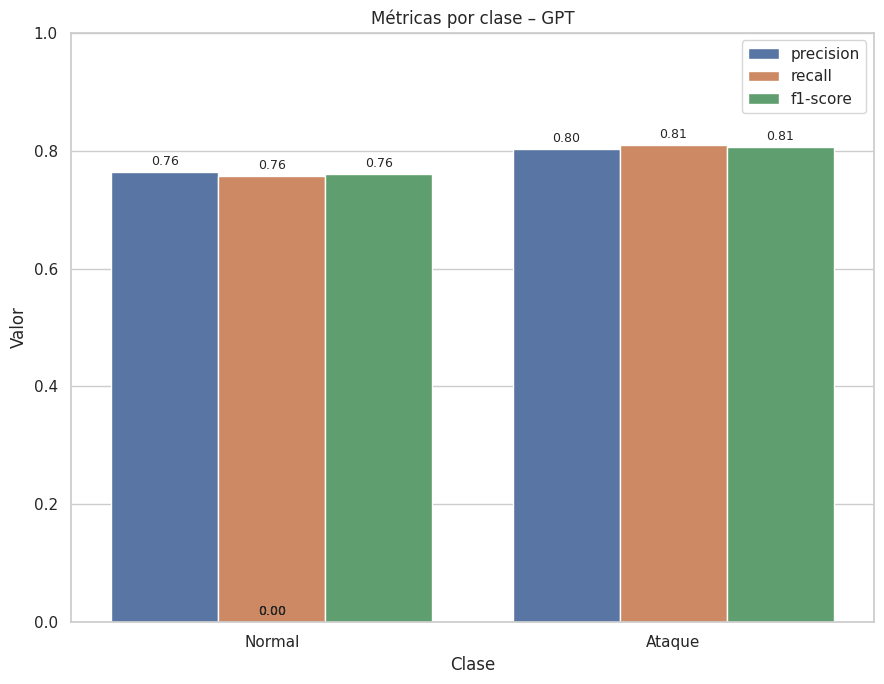

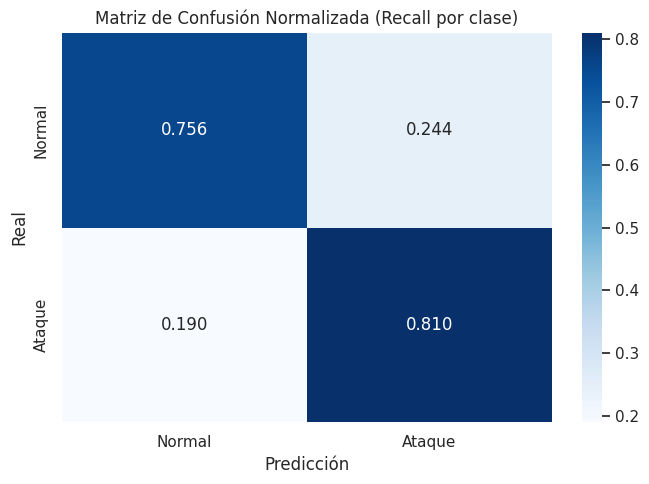

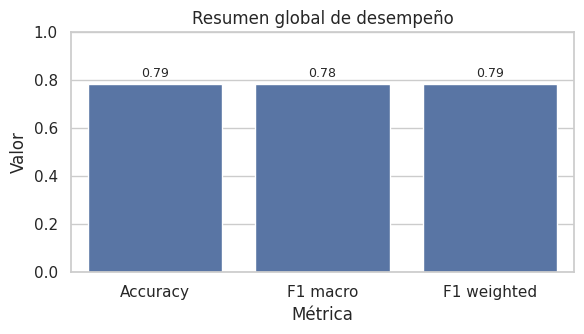

In [ ]:
# Requiere: all_labels, all_preds (del bloque anterior)
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

# ===== 1) Barras por clase: precision / recall / F1 (valores en decimales) =====
rep = classification_report(
    all_labels, all_preds,
    target_names=['Normal','Ataque'],
    output_dict=True, zero_division=0
)
df_metrics = pd.DataFrame(rep).T  # filas: Normal, Ataque, accuracy, macro avg, weighted avg
classes = ['Normal','Ataque']
plot_df = df_metrics.loc[classes, ['precision','recall','f1-score']].reset_index().rename(columns={'index':'Clase'})
plot_df = plot_df.melt(id_vars='Clase', var_name='Métrica', value_name='Valor')

plt.figure(figsize=(9,7))
ax = sns.barplot(data=plot_df, x='Clase', y='Valor', hue='Métrica')
ax.set_ylim(0,1)
ax.set_title('Métricas por clase – GPT')
ax.set_ylabel('Valor')

# Etiquetas en cada barra (decimales)
for p in ax.patches:
    val = p.get_height()
    ax.annotate(f'{val:.2f}',
                (p.get_x() + p.get_width()/2., val),
                ha='center', va='bottom', fontsize=9, xytext=(0,3), textcoords='offset points')
ax.legend(title='', loc='upper right')
plt.tight_layout()
plt.show()

# ===== 2) Matriz de confusión normalizada (decimales, recall por clase) =====
cm = confusion_matrix(all_labels, all_preds, labels=[0,1])
cm_norm = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(7,5))
ax = sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues',
                 xticklabels=['Normal','Ataque'], yticklabels=['Normal','Ataque'])
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title('Matriz de Confusión Normalizada (Recall por clase)')
plt.tight_layout()
plt.show()

# ===== 3) Resumen global: accuracy, F1 macro, F1 weighted (decimales) =====
acc = accuracy_score(all_labels, all_preds)
f1_macro  = df_metrics.loc['macro avg','f1-score']
f1_weight = df_metrics.loc['weighted avg','f1-score']

summary_df = pd.DataFrame({
    'Métrica': ['Accuracy','F1 macro','F1 weighted'],
    'Valor':   [acc, f1_macro, f1_weight]
})

plt.figure(figsize=(6,3.5))
ax = sns.barplot(data=summary_df, x='Métrica', y='Valor')
ax.set_ylim(0,1)
ax.set_title('Resumen global de desempeño')

for p in ax.patches:
    val = p.get_height()
    ax.annotate(f'{val:.2f}',
                (p.get_x() + p.get_width()/2., val),
                ha='center', va='bottom', fontsize=9, xytext=(0,3), textcoords='offset points')
plt.tight_layout()
plt.show()


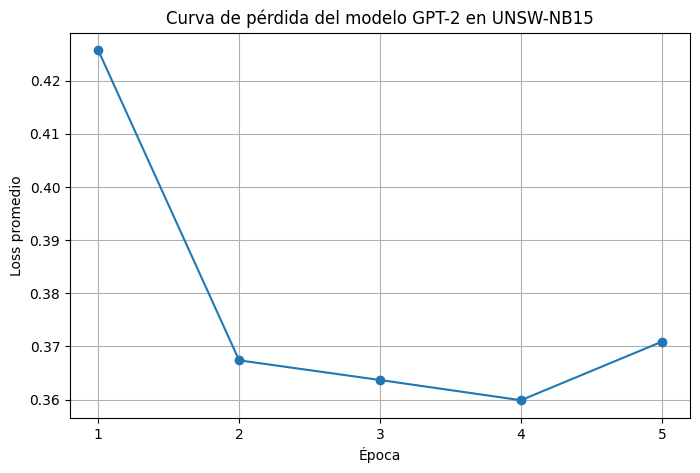

In [ ]:
import matplotlib.pyplot as plt

# Supongamos que guardaste los losses por época en una lista
# Ejemplo con tus valores:
epoch_losses = [0.4257, 0.3674, 0.3637, 0.3599, 0.3709]

# Graficar
plt.figure(figsize=(8,5))
plt.plot(range(1, len(epoch_losses)+1), epoch_losses, marker='o', linestyle='-')
plt.xlabel("Época")
plt.ylabel("Loss promedio")
plt.title("Curva de pérdida del modelo GPT-2 en UNSW-NB15")
plt.xticks(range(1, len(epoch_losses)+1))
plt.grid(True)
plt.show()
